<p style ="text-align:center">
    <img src="https://raw.githubusercontent.com/EduPekUfpr/PythonProject/refs/heads/main/Images/BannerUFPR.png" width="700" alt="PPGOLD/PPGMNE Python:INTRO"  />
</p>


# Liga Data Science
## Prof. Eduardo Pécora

# Análise de Componentes Principais (PCA) · 2. Um índice construído pelos dados
Tempo estimado: **30** minutos

-----

## Objetivos

Após completar esta aula, você será capaz de:

* Explicar por que padronizar as variáveis antes da PCA
* Escolher o número de componentes com mais de um critério
* Interpretar as cargas e dar significado às componentes
* Construir um índice com a PC1 e compará-lo com um índice oficial (IDHM)

No notebook anterior vimos, com as notas de uma turma, o que a PCA faz. Agora a aplicamos a um problema real: **resumir 12 indicadores sociais dos 27 estados brasileiros em poucos números**.

> **Revisão rápida**
> - A PCA **gira os eixos**: a 1ª componente (PC1) aponta para onde os dados mais variam; a PC2 é perpendicular e fica com o que sobrou.
> - Cada componente é uma combinação das variáveis; os pesos se chamam **cargas**.
> - A variância total não muda: ela só se **concentra** nas primeiras componentes.

| Parte | Pergunta | Tempo sugerido |
|---|---|---|
| **1** | Por que é preciso padronizar antes da PCA? | ~5 min |
| **2** | Dá para criar um índice de desenvolvimento a partir dos dados? | ~25 min |

Sequência da aula:
1. `PPGOLD_DS_9_1_PCA_Intuicao.ipynb` — intuição (notas da turma)
2. **`PPGOLD_DS_9_2_PCA_Atlas.ipynb`** — este notebook (indicadores dos estados)
3. `PPGOLD_DS_9_3_PCA_Modelos.ipynb` — PCA dentro de um modelo preditivo

### Como trabalhar
- As células com **Tarefa N** são suas: leia o enunciado e escreva o código na célula logo abaixo.
- As demais células já estão prontas: apenas execute.
- Onde aparece **Sua resposta**, escreva em uma ou duas frases o que você concluiu.

#### Começamos importando as bibliotecas e fixando a semente aleatória

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

np.random.seed(31415)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

---
# Parte 1 — Por que padronizar?

Agora vamos aos dados reais: **indicadores sociais das 27 Unidades da Federação** no Censo 2010, do *Atlas do Desenvolvimento Humano no Brasil* (PNUD, Ipea e Fundação João Pinheiro).

| Coluna | Significado | Unidade |
|---|---|---|
| `esperanca_vida` | Esperança de vida ao nascer | anos |
| `mortalidade_infantil` | Óbitos antes de 1 ano por mil nascidos vivos | por mil |
| `fecundidade` | Filhos por mulher | filhos |
| `anos_estudo_esperados` | Anos de estudo esperados aos 18 anos | anos |
| `analfabetismo_15mais` | % de analfabetos com 15 anos ou mais | % |
| `superior_25mais` | % com superior completo, 25 anos ou mais | % |
| `renda_per_capita` | Renda domiciliar per capita média | R$ de ago/2010 |
| `gini` | Índice de Gini (desigualdade de renda) | 0 a 1 |
| `pct_pobres` | % de pobres (renda per capita ≤ R$ 140) | % |
| `desemprego` | Taxa de desocupação, 18 anos ou mais | % |
| `trabalho_formal` | % dos ocupados com trabalho formal | % |
| `agua_esgoto_inadequado` | % em domicílios com água e esgoto inadequados | % |
| `idhm` | IDH Municipal oficial do estado (**não entra na PCA**) | 0 a 1 |

> **O IDHM fica de fora de propósito.** No fim da Parte 2 vamos comparar o índice que a PCA constrói sozinha com o IDHM oficial.

#### Lendo os dados

Coloque o arquivo `atlas_brasil_uf_2010.csv` na mesma pasta do notebook (no Colab, use o ícone de pasta à esquerda → *upload*), ou troque o caminho abaixo pela URL do repositório da disciplina.

In [2]:
ARQUIVO = "atlas_brasil_uf_2010.csv"   # ou a URL raw do GitHub da disciplina

df = pd.read_csv(ARQUIVO)
indicadores = df.columns[3:-1]          # as 12 variáveis (sem sigla, estado, região e IDHM)

print(df.shape)
print(list(indicadores))
df.head()

(27, 16)
['esperanca_vida', 'mortalidade_infantil', 'fecundidade', 'anos_estudo_esperados', 'analfabetismo_15mais', 'superior_25mais', 'renda_per_capita', 'gini', 'pct_pobres', 'desemprego', 'trabalho_formal', 'agua_esgoto_inadequado']


,sigla,estado,regiao,esperanca_vida,mortalidade_infantil,fecundidade,anos_estudo_esperados,analfabetismo_15mais,superior_25mais,renda_per_capita,gini,pct_pobres,desemprego,trabalho_formal,agua_esgoto_inadequado,idhm
0,RO,Rondônia,Norte,72.97,18.02,2.16,9.20,8.73,8.04,670.82,0.56,14.80,5.19,51.72,12.43,0.690
1,AC,Acre,Norte,71.63,23.01,2.95,8.69,16.48,8.98,522.15,0.63,29.46,7.46,46.45,28.09,0.663
2,AM,Amazonas,Norte,73.30,17.01,2.59,8.54,9.84,8.23,539.80,0.65,30.78,9.55,44.56,20.98,0.674
3,RR,Roraima,Norte,73.51,16.11,2.41,8.69,10.33,10.16,605.59,0.63,26.65,7.60,47.99,12.44,0.707
4,PA,Pará,Norte,72.36,20.29,2.50,8.49,11.74,6.21,446.76,0.62,32.33,9.03,37.38,29.05,0.646


### Tarefa 1 — As escalas são comparáveis?
1. Use `.describe()` nos 12 indicadores.
2. Calcule a **variância** de cada indicador e ordene da maior para a menor (`.var().sort_values(ascending=False)`).

Compare a variância de `renda_per_capita` com a de `gini`. Lembrando do notebook das notas: o que a PCA vai "achar" que é a direção mais importante?

In [3]:
# Tarefa 1 — gabarito
display(df[indicadores].describe().T)
df[indicadores].var().sort_values(ascending=False)

,count,mean,std,min,25%,50%,75%,max
esperanca_vida,27.0,73.513,1.825,70.32,72.160,73.30,75.030,77.35
mortalidade_infantil,27.0,18.178,4.477,11.54,14.150,18.02,21.050,28.40
fecundidade,27.0,2.078,0.331,1.66,1.830,1.99,2.315,2.95
anos_estudo_esperados,27.0,9.394,0.548,8.49,9.100,9.29,9.810,10.43
analfabetismo_15mais,27.0,12.089,6.519,3.47,7.805,9.84,18.200,24.33
superior_25mais,27.0,10.113,3.695,5.43,8.015,10.16,11.170,23.95
renda_per_capita,27.0,696.974,289.246,360.34,509.440,598.98,813.200,1715.11
gini,27.0,0.591,0.039,0.49,0.560,0.60,0.620,0.65
pct_pobres,27.0,19.882,11.475,3.65,8.560,23.79,29.195,39.53
desemprego,27.0,7.679,2.136,3.40,6.045,7.58,9.290,11.49


renda_per_capita          83663.142
trabalho_formal             131.952
pct_pobres                  131.669
agua_esgoto_inadequado       73.724
analfabetismo_15mais         42.497
mortalidade_infantil         20.042
superior_25mais              13.656
desemprego                    4.561
esperanca_vida                3.332
anos_estudo_esperados         0.301
fecundidade                   0.110
gini                          0.002
dtype: float64

**Resposta (gabarito):** A variância da renda (em R$², na casa das dezenas de milhares) é milhões de vezes maior que a do Gini (≈ 0,001). Como a PCA procura a direção de maior variância, ela vai apontar quase toda para a renda, só por causa da **unidade de medida**.

### Tarefa 2 — PCA sem e com padronização
1. Ajuste `PCA()` aos 12 indicadores **sem padronizar** e mostre:
   - `explained_variance_ratio_[:3]`
   - as cargas da PC1 como uma `pd.Series` com os nomes dos indicadores.
2. Repita **padronizando antes** com `StandardScaler().fit_transform(...)`.

O que muda nas cargas da PC1?

In [4]:
# Tarefa 2 — gabarito
X = df[indicadores]

# (a) sem padronizar
pca_bruta = PCA().fit(X)
print("SEM padronizar — variância explicada:", pca_bruta.explained_variance_ratio_[:3].round(4))
print(pd.Series(pca_bruta.components_[0], index=indicadores).round(3), "\n")

# (b) padronizando
X_pad = StandardScaler().fit_transform(X)
pca_pad = PCA().fit(X_pad)
print("COM padronização — variância explicada:", pca_pad.explained_variance_ratio_[:3].round(4))
print(pd.Series(pca_pad.components_[0], index=indicadores).round(3))

SEM padronizar — variância explicada: [9.983e-01 1.100e-03 4.000e-04]
esperanca_vida            0.006
mortalidade_infantil     -0.011
fecundidade              -0.001
anos_estudo_esperados     0.001
analfabetismo_15mais     -0.018
superior_25mais           0.012
renda_per_capita          0.998
gini                     -0.000
pct_pobres               -0.033
desemprego               -0.003
trabalho_formal           0.035
agua_esgoto_inadequado   -0.020
dtype: float64 

COM padronização — variância explicada: [0.7103 0.1086 0.0834]
esperanca_vida           -0.326
mortalidade_infantil      0.300
fecundidade               0.245
anos_estudo_esperados    -0.255
analfabetismo_15mais      0.293
superior_25mais          -0.274
renda_per_capita         -0.301
gini                      0.261
pct_pobres                0.335
desemprego                0.240
trabalho_formal          -0.329
agua_esgoto_inadequado    0.283
dtype: float64


**Resposta (gabarito):** Sem padronizar, a PC1 "explica" 99,8% da variância, mas é praticamente só a renda (carga ≈ 1; todas as outras ≈ 0). É um **falso sucesso**: a PCA só redescobriu a variável medida na maior unidade.

Padronizando (média 0, desvio 1), todas as variáveis entram no mesmo pé, e a PC1 passa a combinar **todos** os indicadores, explicando ≈ 71%.

**Regra prática:** variáveis em unidades diferentes → padronize antes da PCA.

---
# Parte 2 — Um índice de desenvolvimento construído pelos dados

Daqui em diante usamos os dados **padronizados**.

In [5]:
X_pad = StandardScaler().fit_transform(df[indicadores])
pca = PCA().fit(X_pad)

nomes_pc = [f"PC{i+1}" for i in range(len(indicadores))]
print(f"{X_pad.shape[1]} variáveis  ->  {pca.n_components_} componentes possíveis")

12 variáveis  ->  12 componentes possíveis


### Tarefa 3 — Quanta informação cada componente guarda?
1. Monte um `DataFrame` chamado `tabela` com uma linha por componente e as colunas:
   - `autovalor` → `pca.explained_variance_`
   - `% variância` → `pca.explained_variance_ratio_ * 100`
   - `% acumulada` → a soma acumulada da coluna anterior (`.cumsum()`)
2. Faça um gráfico com **barras** para a `% variância` e uma **linha** para a `% acumulada` (os dois em %, no mesmo eixo).

,autovalor,% variância,% acumulada
PC1,8.85,71.03,71.03
PC2,1.35,10.86,81.89
PC3,1.04,8.34,90.23
PC4,0.53,4.22,94.45
PC5,0.29,2.34,96.79
PC6,0.17,1.35,98.14
PC7,0.09,0.75,98.89
PC8,0.05,0.39,99.28
PC9,0.03,0.28,99.56
PC10,0.03,0.24,99.80


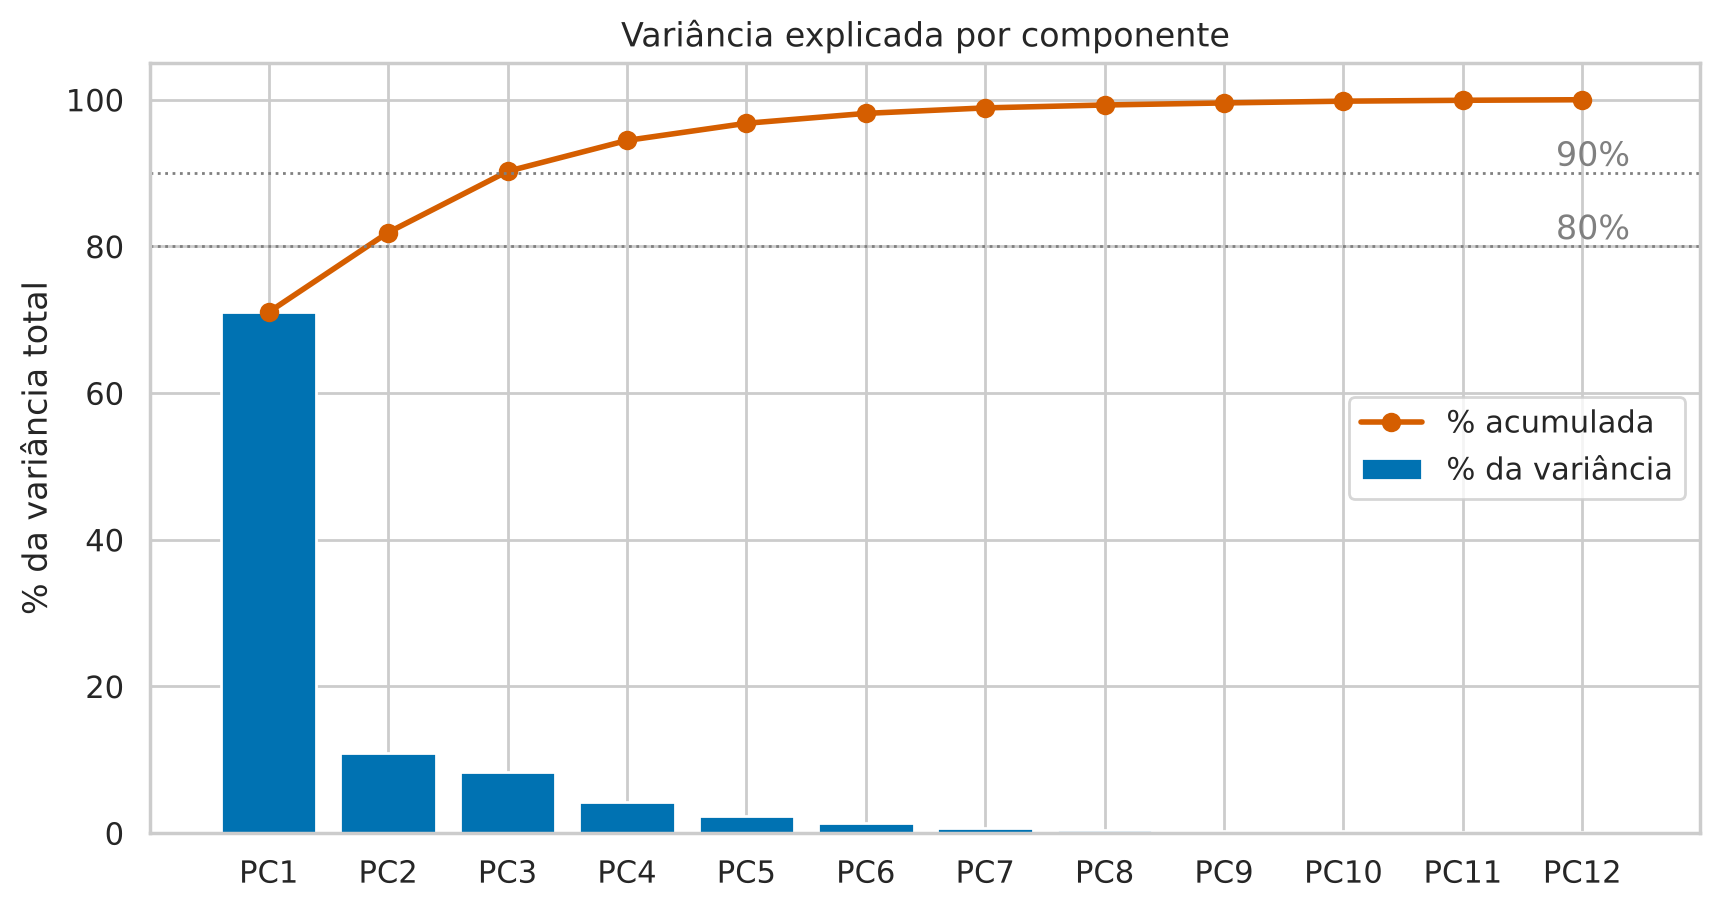

In [6]:
# Tarefa 3 — gabarito
tabela = pd.DataFrame({
    "autovalor": pca.explained_variance_,
    "% variância": pca.explained_variance_ratio_ * 100,
}, index=nomes_pc)
tabela["% acumulada"] = tabela["% variância"].cumsum()
display(tabela.round(2))

plt.figure(figsize=(10, 5))
plt.bar(nomes_pc, tabela["% variância"], color="#0072B2", label="% da variância")
plt.plot(nomes_pc, tabela["% acumulada"], color="#D55E00", marker="o", lw=2, label="% acumulada")
for limite in [80, 90]:
    plt.axhline(limite, color="grey", ls=":", lw=1)
    plt.text(len(nomes_pc) - 0.6, limite + 1, f"{limite}%", color="grey", ha="right")
plt.ylabel("% da variância total")
plt.ylim(0, 105)
plt.title("Variância explicada por componente")
plt.legend(loc="center right")
plt.show()

### Tarefa 4 — Quantas componentes manter?
Não existe resposta única; usamos critérios e comparamos.

1. **Critério da variância acumulada:** quantas componentes são necessárias para chegar a **80%**? E a **90%**?
2. **Critério de Kaiser:** com dados padronizados, cada variável original tem variância 1. Uma componente só "vale a pena" se guardar **mais que uma variável**, isto é, se tiver **autovalor > 1**. Quantas componentes passam?

Dica: `(tabela["% acumulada"] < 80).sum() + 1` e `(tabela["autovalor"] > 1).sum()`.

In [7]:
# Tarefa 4 — gabarito
k80 = (tabela["% acumulada"] < 80).sum() + 1
k90 = (tabela["% acumulada"] < 90).sum() + 1
k_kaiser = (tabela["autovalor"] > 1).sum()

print(f"Para 80% da variância: {k80} componentes")
print(f"Para 90% da variância: {k90} componentes")
print(f"Critério de Kaiser (autovalor > 1): {k_kaiser} componentes")

Para 80% da variância: 2 componentes
Para 90% da variância: 3 componentes
Critério de Kaiser (autovalor > 1): 3 componentes


**Resposta (gabarito):** 2 componentes passam de 80% (≈ 82%); 3 passam de 90% (≈ 90,2%, por pouco); Kaiser também indica 3. Saímos de **12 indicadores para 2 ou 3 números** perdendo de 10% a 18% da informação. Para visualizar usamos 2; para alimentar um modelo, 3 seria uma escolha defensável.

### Tarefa 5 — O que cada componente significa?
1. Monte um `DataFrame` chamado `cargas` com as cargas das **3 primeiras** componentes: linhas = indicadores, colunas = `PC1`, `PC2`, `PC3`.
   Dica: `pca.components_[:3].T`.
2. Execute a célula seguinte (já pronta), que desenha o mapa de calor das cargas.
3. Responda: quais indicadores têm carga **positiva** forte na PC1? Quais têm carga **negativa**? Que nome você daria à PC1? E à PC2?

In [8]:
# Tarefa 5 — gabarito
cargas = pd.DataFrame(pca.components_[:3].T, index=indicadores, columns=["PC1", "PC2", "PC3"])
cargas.round(2)

,PC1,PC2,PC3
esperanca_vida,-0.33,0.19,0.07
mortalidade_infantil,0.30,-0.13,-0.23
fecundidade,0.25,0.25,0.56
anos_estudo_esperados,-0.26,-0.32,-0.13
analfabetismo_15mais,0.29,-0.26,-0.36
superior_25mais,-0.27,0.43,-0.20
renda_per_capita,-0.30,0.33,-0.15
gini,0.26,0.47,-0.27
pct_pobres,0.34,0.01,-0.06
desemprego,0.24,0.36,-0.43


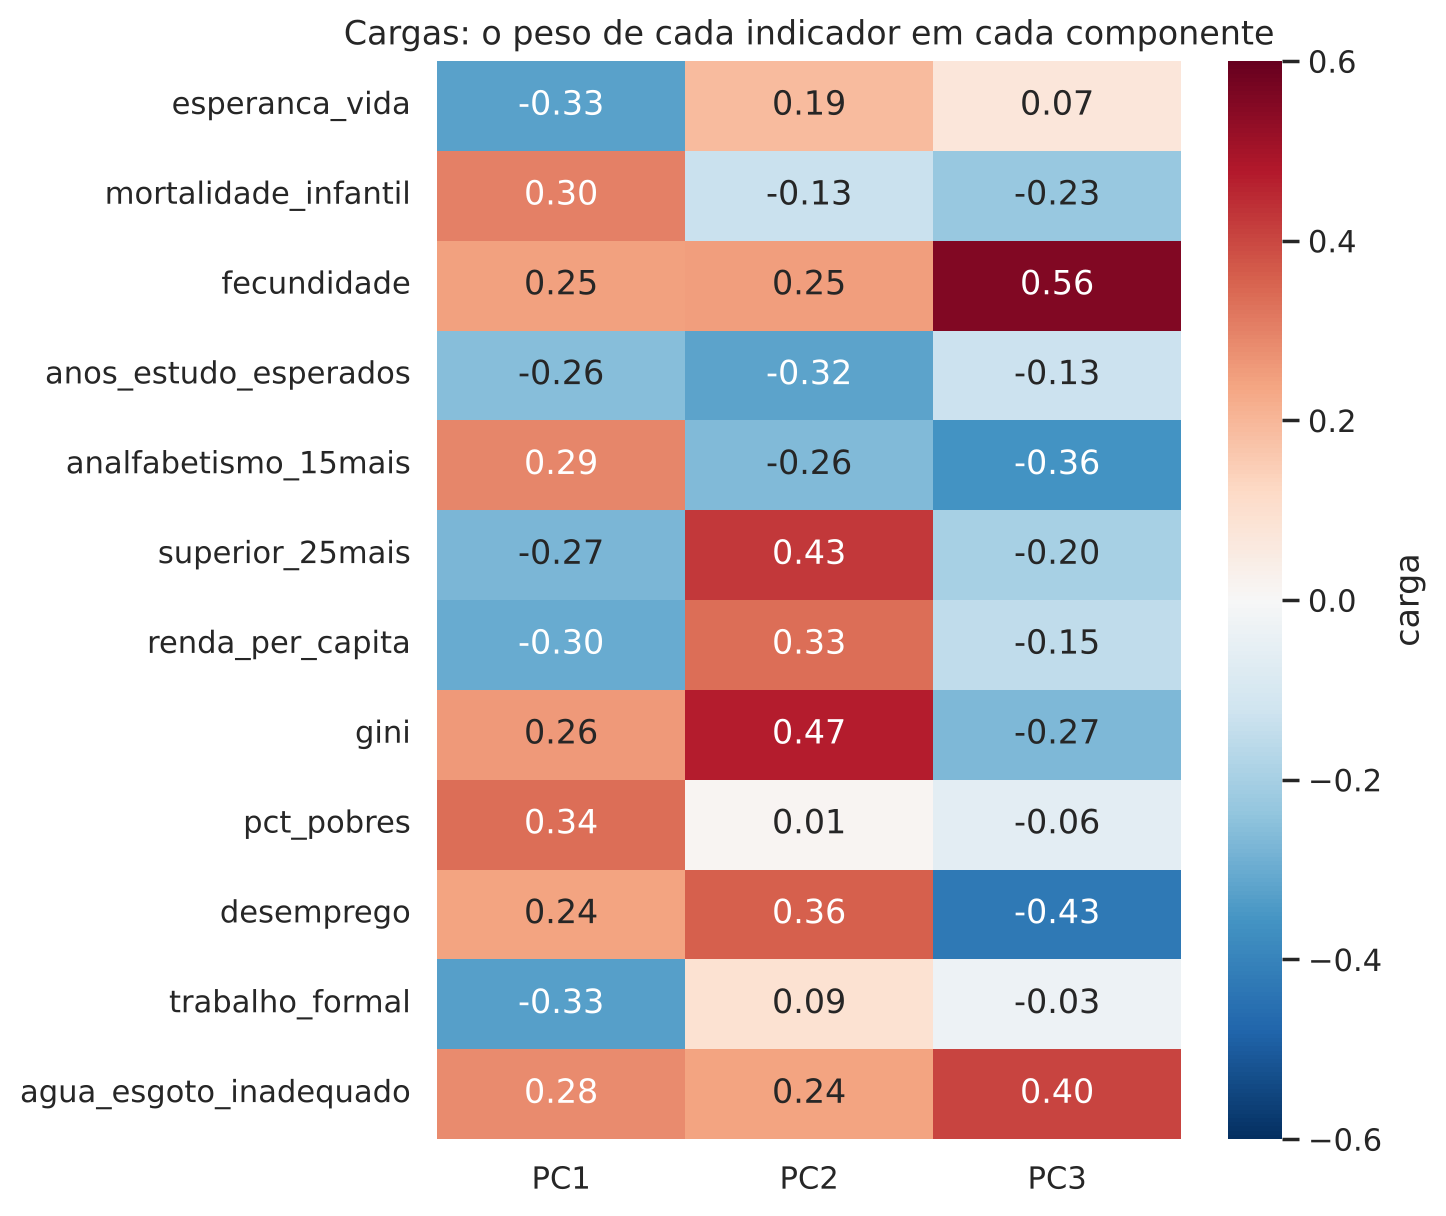

In [9]:
if not isinstance(globals().get("cargas"), pd.DataFrame):
    print("Complete a Tarefa 5: crie o DataFrame cargas antes de rodar esta célula.")
else:
    plt.figure(figsize=(6, 7))
    sns.heatmap(cargas, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.6,
                cbar_kws={"label": "carga"})
    plt.title("Cargas: o peso de cada indicador em cada componente")
    plt.show()

**Resposta (gabarito):** *(Os sinais podem vir todos trocados em outra versão do scikit-learn; a leitura é a mesma, só invertida.)*

**PC1:** de um lado estão mortalidade infantil, % de pobres, analfabetismo, água e esgoto inadequados e fecundidade; do outro, esperança de vida, trabalho formal, renda, % com superior e anos de estudo. Quase todos os indicadores têm carga de tamanho parecido: a PC1 é um eixo geral de **desenvolvimento** (ou de subdesenvolvimento, conforme o sinal).

**PC2:** carga forte e de mesmo sinal em Gini, % com superior, desemprego e renda, e sinal oposto em anos de estudo esperados e analfabetismo. Ela separa estados com **renda e escolaridade superior concentradas, mas com desigualdade e desemprego altos**, e não tem a ver com "ser mais ou menos desenvolvido". Um nome possível: **desigualdade urbana / concentração**.

### Tarefa 6 — Onde fica cada estado?
1. Crie um `DataFrame` chamado `scores` com as duas primeiras colunas de `pca.transform(X_pad)` (nomes `PC1` e `PC2`) e acrescente as colunas `sigla` e `regiao` de `df`.
2. Execute a célula seguinte, que desenha o **biplot**: os estados (pontos) e as cargas (setas) no mesmo gráfico.
3. Responda: quais estados ficam nos extremos da PC1? Por que o **Distrito Federal** fica isolado no alto (ou embaixo) da PC2?

In [10]:
# Tarefa 6 — gabarito
Z = pca.transform(X_pad)
scores = pd.DataFrame(Z[:, :2], columns=["PC1", "PC2"])
scores["sigla"] = df["sigla"]
scores["regiao"] = df["regiao"]
scores.head()

,PC1,PC2,sigla,regiao
0,-0.257,-0.745,RO,Norte
1,3.460,1.169,AC,Norte
2,2.510,1.927,AM,Norte
3,1.141,1.229,RR,Norte
4,3.462,0.984,PA,Norte


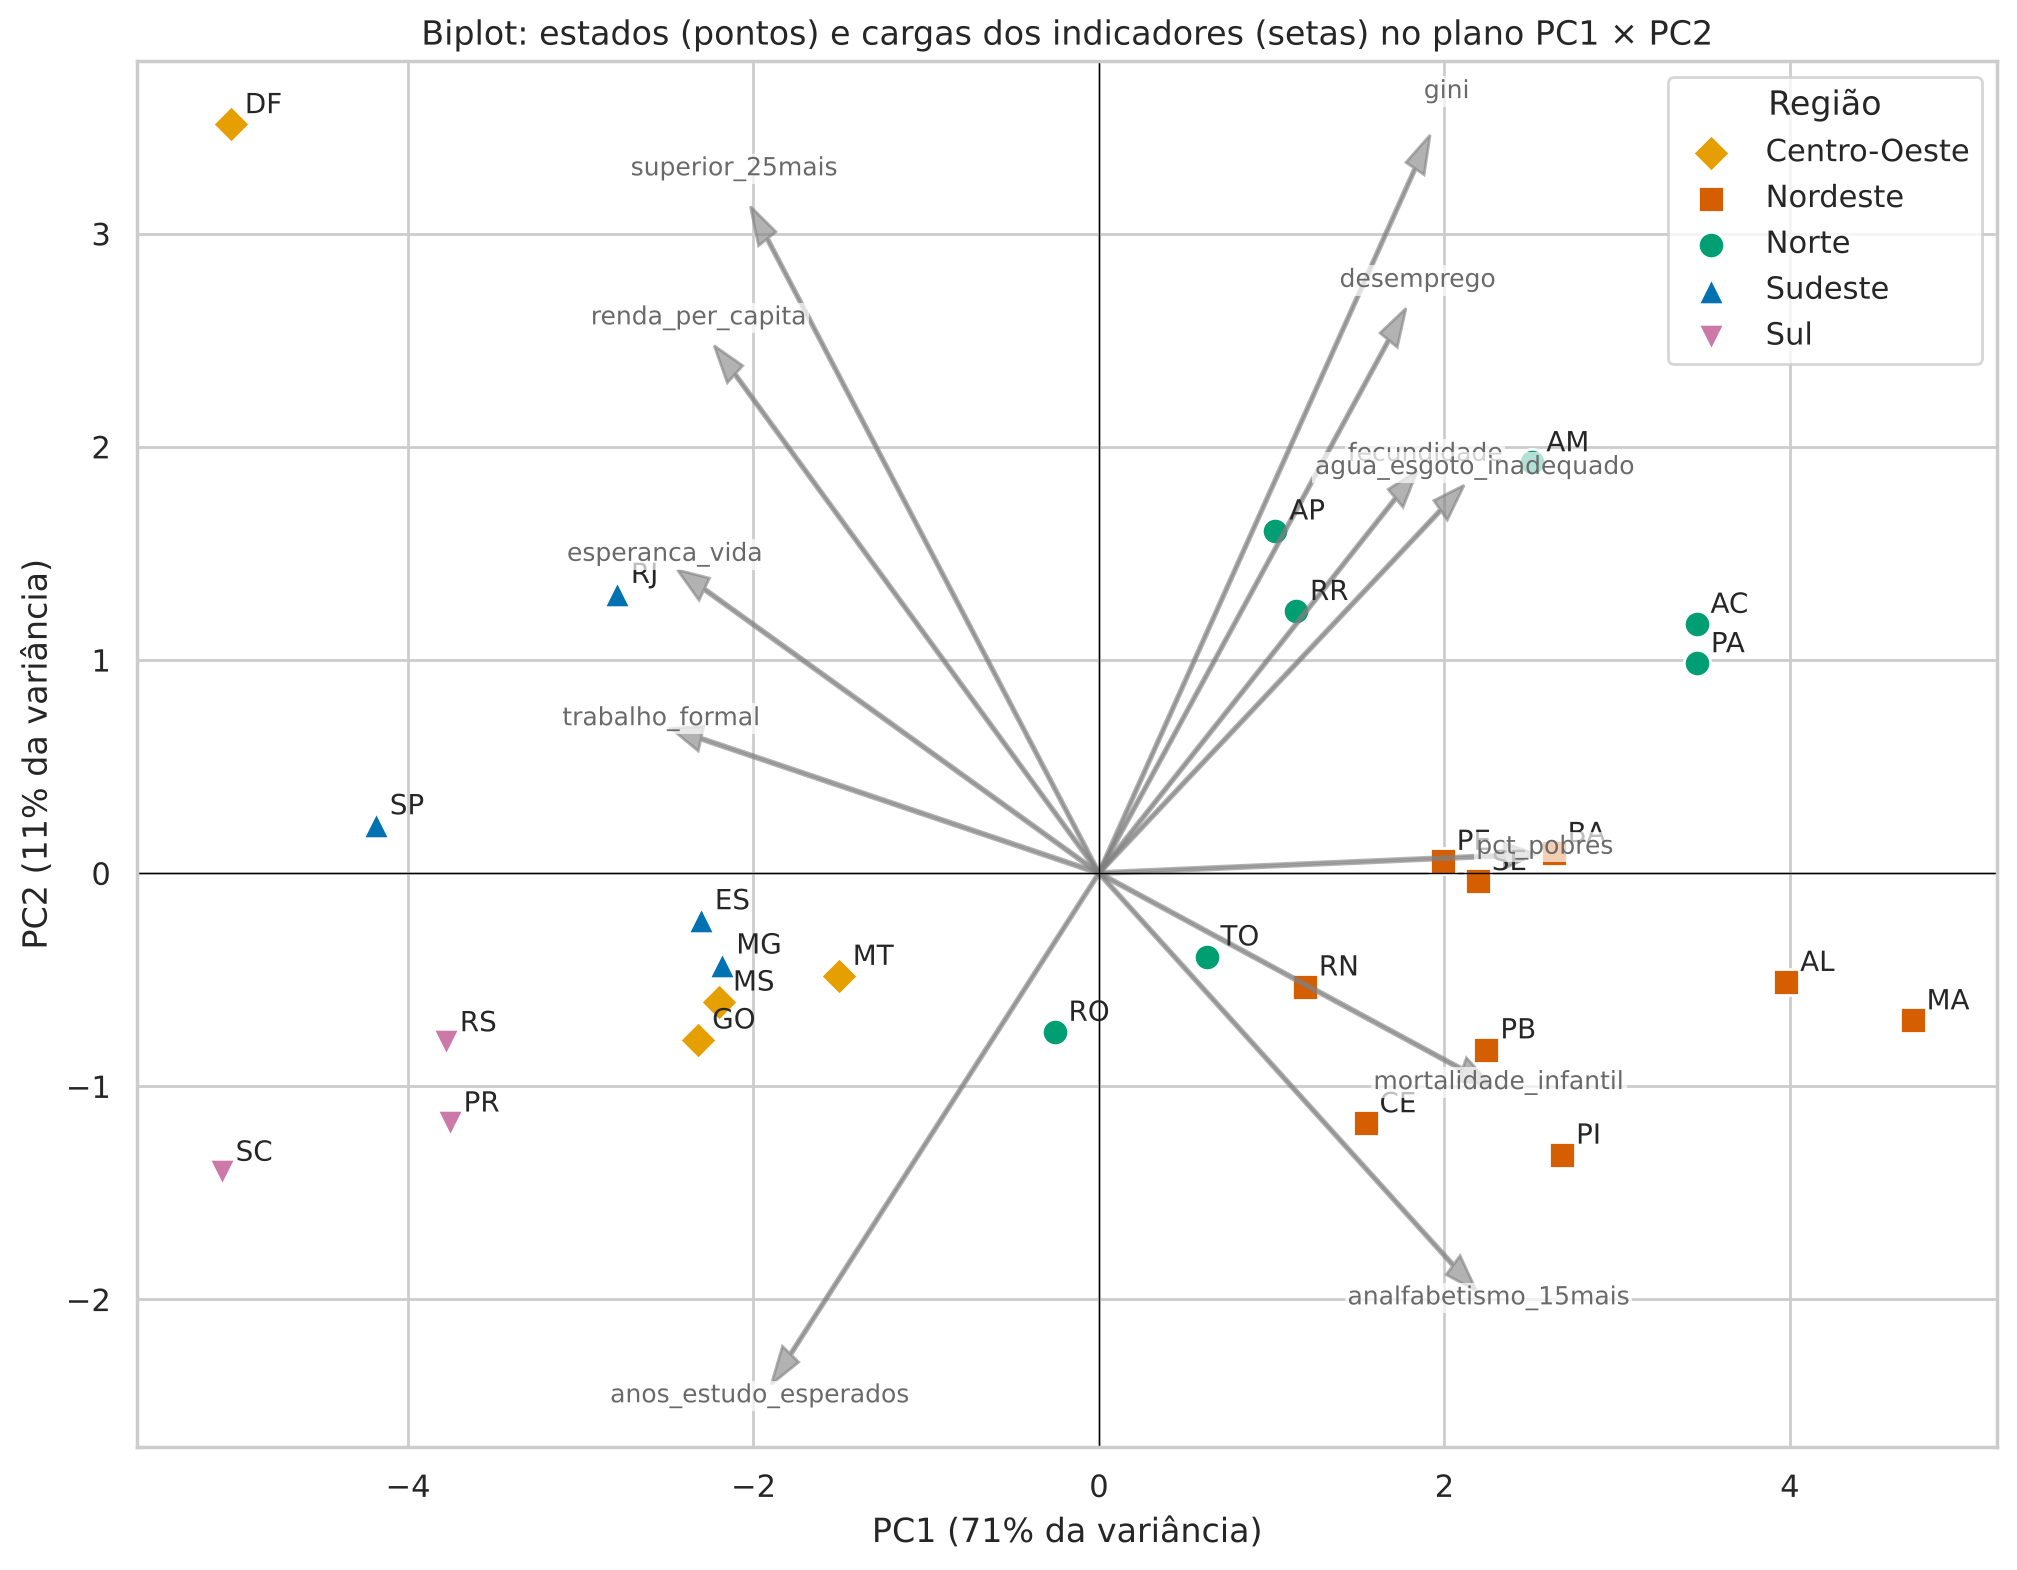

In [11]:
if not isinstance(globals().get("scores"), pd.DataFrame):
    raise SystemExit("Complete a Tarefa 6: crie o DataFrame scores antes de rodar esta célula.")

MOSTRAR_CARGAS = True   # False = só os estados no plano PC1 × PC2

cores = {"Norte": "#009E73", "Nordeste": "#D55E00", "Centro-Oeste": "#E69F00",
         "Sudeste": "#0072B2", "Sul": "#CC79A7"}
marcadores = {"Norte": "o", "Nordeste": "s", "Centro-Oeste": "D", "Sudeste": "^", "Sul": "v"}

fig, ax = plt.subplots(figsize=(12, 9))

# Pontos: cada estado posicionado pelos seus scores na PC1 e na PC2
for reg, grupo in scores.groupby("regiao"):
    ax.scatter(grupo["PC1"], grupo["PC2"], s=90, color=cores[reg], marker=marcadores[reg],
               label=reg, edgecolor="white", linewidth=1)
for _, linha in scores.iterrows():
    ax.annotate(linha["sigla"], (linha["PC1"], linha["PC2"]), xytext=(5, 4),
                textcoords="offset points", fontsize=10)

# Setas (opcional): carga de cada indicador na PC1 (horizontal) e na PC2 (vertical)
if MOSTRAR_CARGAS:
    escala = 7   # só para as setas ficarem visíveis na mesma escala dos pontos
    for var, (c1, c2) in cargas[["PC1", "PC2"]].iterrows():
        ax.arrow(0, 0, escala * c1, escala * c2, color="grey", alpha=0.6, width=0.015, head_width=0.12)
        ax.text(escala * c1 * 1.1, escala * c2 * 1.1, var, color="dimgrey", fontsize=9, ha="center",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1))
    ax.set_title("Biplot: estados (pontos) e cargas dos indicadores (setas) no plano PC1 × PC2")
else:
    ax.set_title("Estados no plano das duas primeiras componentes principais")

ax.axhline(0, color="black", lw=0.5); ax.axvline(0, color="black", lw=0.5)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} da variância)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} da variância)")
ax.legend(title="Região")
plt.show()

**Resposta (gabarito):** Na PC1, Maranhão e Alagoas ficam em um extremo; Santa Catarina, Distrito Federal e São Paulo no outro. Os estados se organizam quase por região, mesmo sem a PCA saber a região de ninguém.

O DF tem a maior renda e o maior % com ensino superior do país, mas também Gini e desemprego relativamente altos. Ele é desenvolvido **e** muito desigual, uma combinação que a PC1 não captura e que a PC2 isola. Amazonas, Amapá e Roraima ficam do mesmo lado da PC2 pelo desemprego e pela desigualdade. Santa Catarina e Paraná ficam no lado oposto: menos desigualdade e menos desemprego.

### Tarefa 7 — Nosso índice × IDHM oficial
1. Crie a coluna `indice_pca` em `df` a partir da PC1, **orientada para que valor maior = mais desenvolvido**.
   Dica: se a carga de `esperanca_vida` na PC1 for negativa, multiplique a PC1 por −1. O código `np.sign(cargas.loc["esperanca_vida", "PC1"])` devolve esse sinal.
2. Mostre o **ranking** dos estados pelo `indice_pca` (`sort_values`).
3. Calcule a **correlação** entre `indice_pca` e `idhm` e faça um gráfico de dispersão das duas, com as siglas.

,sigla,estado,regiao,indice_pca,idhm
0,SC,Santa Catarina,Sul,5.078,0.774
1,DF,Distrito Federal,Centro-Oeste,5.025,0.824
2,SP,São Paulo,Sudeste,4.186,0.783
3,RS,Rio Grande do Sul,Sul,3.780,0.746
4,PR,Paraná,Sul,3.759,0.749
5,RJ,Rio de Janeiro,Sudeste,2.790,0.761
6,GO,Goiás,Centro-Oeste,2.319,0.735
7,ES,Espírito Santo,Sudeste,2.304,0.740
8,MS,Mato Grosso do Sul,Centro-Oeste,2.199,0.729
9,MG,Minas Gerais,Sudeste,2.180,0.731


Correlação entre o índice da PCA e o IDHM: 0.961


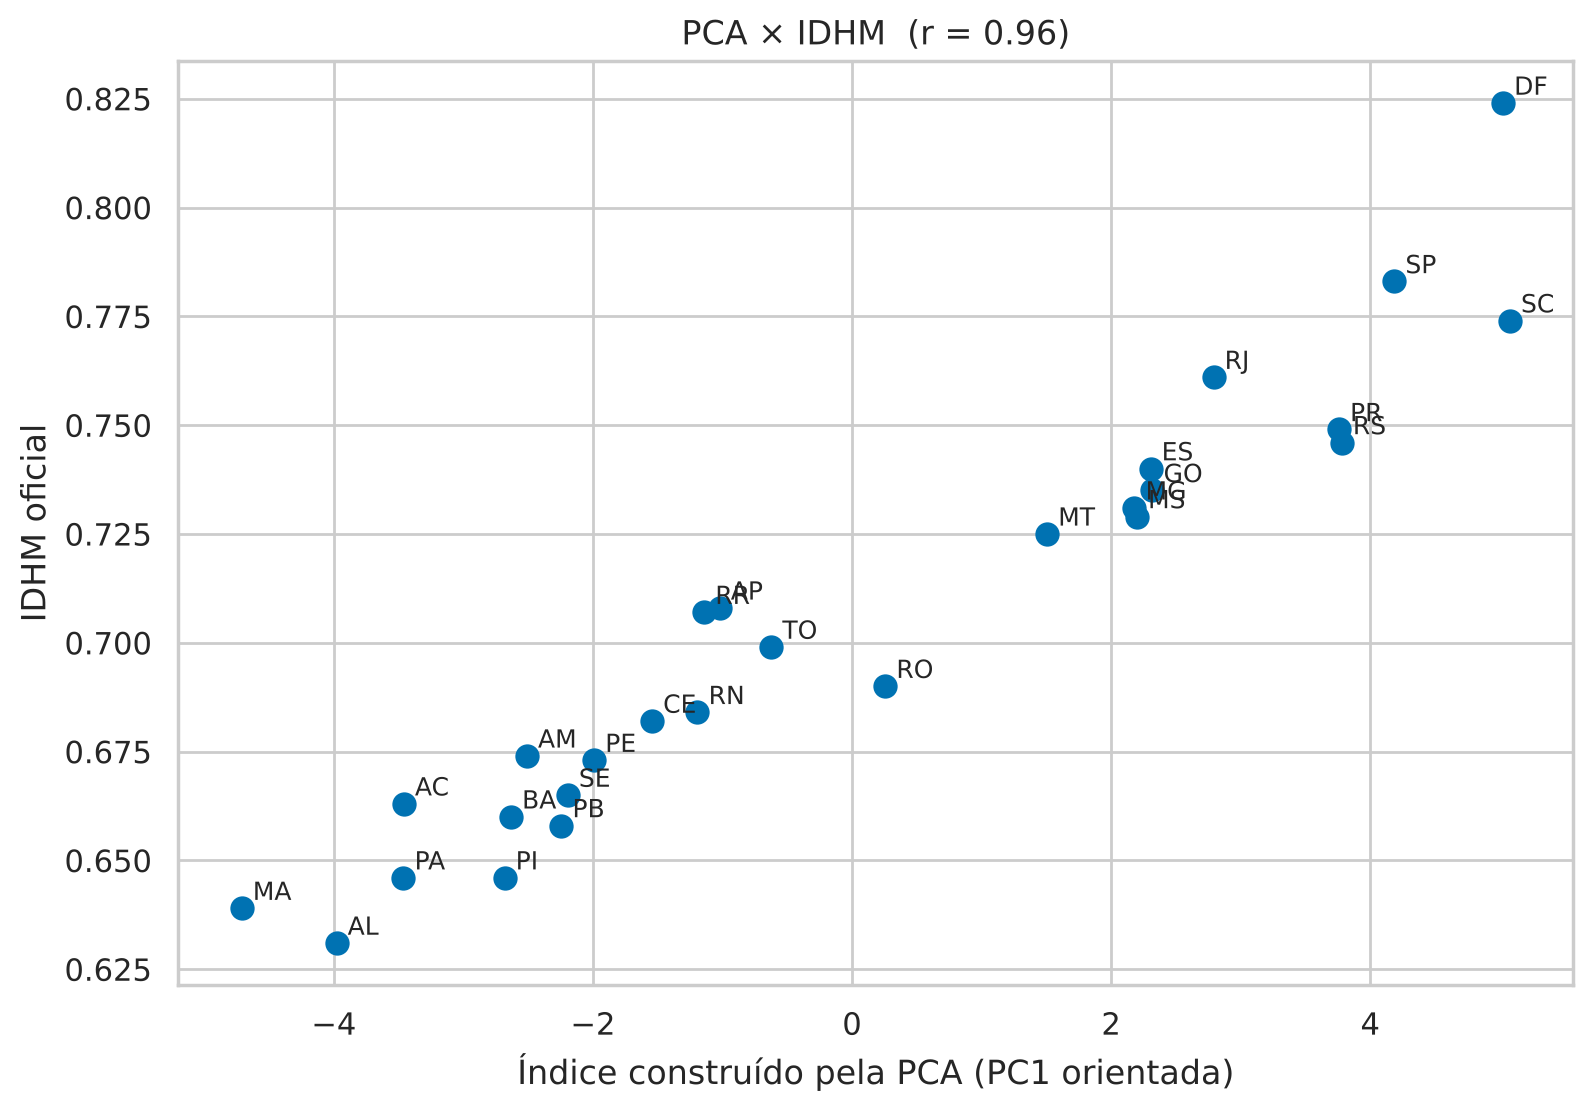

In [12]:
# Tarefa 7 — gabarito
sinal = np.sign(cargas.loc["esperanca_vida", "PC1"])
df["indice_pca"] = sinal * Z[:, 0]

display(df[["sigla", "estado", "regiao", "indice_pca", "idhm"]]
        .sort_values("indice_pca", ascending=False).reset_index(drop=True).round(3))

r = df["indice_pca"].corr(df["idhm"])
print(f"Correlação entre o índice da PCA e o IDHM: {r:.3f}")

plt.figure(figsize=(9, 6))
plt.scatter(df["indice_pca"], df["idhm"], s=60, color="#0072B2")
for _, linha in df.iterrows():
    plt.annotate(linha["sigla"], (linha["indice_pca"], linha["idhm"]), xytext=(4, 3),
                 textcoords="offset points", fontsize=9)
plt.xlabel("Índice construído pela PCA (PC1 orientada)")
plt.ylabel("IDHM oficial")
plt.title(f"PCA × IDHM  (r = {r:.2f})")
plt.show()

**Resposta (gabarito):** A correlação é ≈ 0,96: usando só os dados, **sem decidir peso nenhum**, a PCA reconstruiu praticamente a mesma ordem do IDHM oficial, um índice desenhado por especialistas.

Os limites desse índice:
- Os pesos são decididos pela **variância**, não por um critério de valor: a PCA não sabe o que é "importante" para a sociedade.
- O índice muda se mudarmos as variáveis escolhidas, ou se acrescentarmos estados e anos (os pesos são recalculados).
- A PC1 guarda ≈ 71% da informação; o resto, como a desigualdade do DF, fica de fora.
- A escala do índice não tem unidade: ela serve para **ordenar e comparar**, não para dizer "quanto" um estado é desenvolvido.

---
# Para levar

| Faça | Evite |
|---|---|
| Padronize variáveis com unidades diferentes | PCA em variáveis categóricas codificadas como números |
| Escolha *k* com mais de um critério (acumulada, Kaiser, cotovelo) | Escolher *k* "no olho" sem justificar |
| Interprete as cargas antes de usar os scores | Tratar as PCs como "caixa-preta" |
| Lembre que o sinal é arbitrário | Concluir algo pelo sinal sozinho |
| Use PCA para resumir, visualizar e reduzir colinearidade | Esperar que a PCA capture relações não lineares (ver t-SNE, UMAP) |

**Próximo passo:** no notebook `PPGOLD_DS_9_3_PCA_Modelos.ipynb` usamos a PCA **dentro de um modelo preditivo**, sem cometer vazamento de dados.

## Fique Conectado

- [![YouTube](https://raw.githubusercontent.com/EduPekUfpr/PythonProject/refs/heads/main/Images/youtube_icon_color.png)](https://www.youtube.com/@LigaDataScience/videos)  
  Explore nossos vídeos educacionais e webinars sobre ciência de dados, machine learning e inteligência artificial. Inscreva-se para não perder nenhuma atualização!

- [![LinkedIn](https://raw.githubusercontent.com/EduPekUfpr/PythonProject/refs/heads/main/Images/linkedin_icon_color.png)](https://www.linkedin.com/company/liga-data-science-ufpr/)  
  Siga-nos no LinkedIn para as últimas novidades, oportunidades de carreira e networking profissional no campo da ciência de dados.

- [![Instagram](https://raw.githubusercontent.com/EduPekUfpr/PythonProject/refs/heads/main/Images/instagram_icon_color.png)](https://www.instagram.com/ligadatascience/)  
  Confira nosso Instagram para conteúdos dos bastidores, destaques de eventos e o dia a dia da Liga Data Science. Faça parte da nossa jornada!

_______

## Autor

<a href="https://www.linkedin.com/in/eduardopecora/" target="_blank">Eduardo Pecora</a>

## Referências

* <a href="https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html">Scikit-learn: PCA</a>
* PNUD, Ipea, FJP. <a href="http://www.atlasbrasil.org.br">Atlas do Desenvolvimento Humano no Brasil</a>
* JAMES, G. et al. *An Introduction to Statistical Learning*, cap. 12 (Unsupervised Learning)

## Log de modificações

| Data | Versão | Modificado por | Descrição |
| ----------------- | ------- | ---------- | ---------------------------------- |
| 24-10-2021       | 1.0     | Eduardo Pecora | Criação (aula única de PCA) |
| 09-11-2026       | 2.0     | Claude (a pedido de Eduardo Pécora) | Notebook próprio: padronização e interpretação com os dados do Atlas Brasil, tarefas passo a passo e cabeçalho/rodapé LDS |

<hr>

## <h3 align="center"> (c) LDS / UFPR 2026. All rights reserved. <h3/>